# momentum_solve 최적화 — 회차별 전/후 비교

| 회차 | 꼬리표 | 변경 |
|---|---|---|
| 전 | `h200m`, `v100m` | 변경 전 (`rbc_nob_pre_buildz`) |
| 1 | `h200o`, `v100o` | z 스윕 밴드 조립을 전용 커널 `build_kernel_z`(공유 메모리 (j,k) 타일 전치)로 — `src/equation/momentum/system/system.cu` |
| 2 | `h200t`, `v100t` | + 랭크 내 순환 Thomas `tdma_cycl_many_kernel` 을 레지스터 두 행 버퍼링으로 (논문 2.1 Algorithm 2 방식, z 0 채우기 삭제) — `pascal_tdma_cuda.cu` |

두 회차 모두 산술 식·순서가 같아 결과는 비트 동일해야 한다 (게이트: 스모크 FINAL 0.01503 / 46.0360, 200 스텝 모니터 전 열 일치).

그림은 저장하지 않는다 (노트북 출력만). 데이터: `apps/rbc_nob/scalability/out/`.

In [ ]:
import csv, glob, os, re
from collections import defaultdict
import numpy as np
import matplotlib
try:
    get_ipython().run_line_magic("matplotlib", "inline")
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FixedLocator, NullFormatter, PercentFormatter
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "legend.fontsize": 8, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
OUT_DIR = os.path.abspath(os.path.join(os.getcwd(), "..", "scalability", "out"))

HW_NAME = {"h200": "H200", "a100": "A100", "v100": "V100"}
VERSION = {"m": "before", "o": "after", "t": "after2", "": "before"}   # 꼬리표 접미사 → 버전
VER_LABEL = {"before": "before", "after": "after build_z", "after2": "after build_z + cyclic TDMA"}
VER_COLOR = {"before": "#9a9a96", "after": "#7fa9e3", "after2": "#2a78d6"}   # 전 = 회색, 후 = 파랑 명도 2단
VERS = ["before", "after", "after2"]
HW_COLOR = {"h200": "#2a78d6", "a100": "#eb6834", "v100": "#1baf7a"}
COMPONENTS = ["dU", "dV", "dW"]
EVENTS_PER_COMPONENT = ["build_x", "tdma_x", "scatter_x", "build_y", "tdma_y", "scatter_y",
                        "build_z", "tdma_z", "scatter_z", "halo", "wall_ghost", "couple_rhs"]
EVENTS_POST = ["block_couple_v", "halo_dV", "wall_ghost_dV", "block_couple_u", "add_increment"]
EVENTS = EVENTS_PER_COMPONENT + EVENTS_POST
TOP = ["step_total", "momentum_solve", "scalar_solve", "momentum_rhs", "pressure_solve"]

def load_runs(out_dir=OUT_DIR):
    """{(hw, ver, mode, n, np): [ {phase: max_ms} ]} — momentum 세부 구간이 있는 런만"""
    runs = defaultdict(list)
    for path in sorted(glob.glob(os.path.join(out_dir, "scal_*", "phase_timing_*.csv"))):
        m = re.search(r"scal_(strong|weak)_(\d+)_np(\d+)/phase_timing_([a-z0-9]+)_(\d+)_r(\d+)\.csv$", path)
        if not m:
            continue
        ph = {}
        with open(path) as fh:
            for row in csv.reader(l for l in fh if not l.startswith("#")):
                if row[0] != "phase":
                    ph[row[0]] = float(row[3])
        if not any(k.startswith("momentum.") for k in ph):
            continue
        tag = m.group(4); hw = tag[:4]; suffix = tag[4:]
        if hw not in HW_NAME or suffix not in VERSION:
            continue
        runs[(hw, VERSION[suffix], m.group(1), int(m.group(2)), int(m.group(3)))].append(ph)
    return runs

runs = load_runs()
cases = {k: sorted(v, key=lambda r: r["step_total"])[len(v) // 2] for k, v in runs.items()}

def event_time(ph, event, component=None):
    if event in EVENTS_POST:
        return ph.get(f"momentum.post.{event}", 0.0)
    comps = [component] if component else COMPONENTS
    return sum(ph.get(f"momentum.{c}.{event}", 0.0) for c in comps)

print(f"{len(cases)} cases")
for k in sorted(cases):
    print(f"  {k[0]:5s} {k[1]:6s} {k[2]:6s} {k[3]}^3 np{k[4]:<2d}  step {cases[k]['step_total']:7.1f}  momentum {cases[k]['momentum_solve']:6.1f}  build_z {event_time(cases[k], 'build_z'):6.2f} ms/step  (x{len(runs[k])})")

45 cases
  h200  after  strong 256^3 np1   step    39.8  momentum   17.9  build_z   1.81 ms/step  (x2)
  h200  after  strong 256^3 np2   step    25.3  momentum   12.3  build_z   0.93 ms/step  (x2)
  h200  after  strong 256^3 np4   step    16.9  momentum    8.8  build_z   0.51 ms/step  (x2)
  h200  after  strong 512^3 np1   step   292.6  momentum  122.6  build_z  14.10 ms/step  (x2)
  h200  after  strong 512^3 np2   step   154.8  momentum   67.2  build_z   7.08 ms/step  (x2)
  h200  after  strong 512^3 np4   step    82.8  momentum   37.6  build_z   3.60 ms/step  (x2)
  h200  after  weak   256^3 np1   step    39.8  momentum   17.9  build_z   1.81 ms/step  (x2)
  h200  after  weak   256^3 np2   step    42.5  momentum   19.5  build_z   1.80 ms/step  (x2)
  h200  after  weak   256^3 np4   step    42.7  momentum   19.8  build_z   1.80 ms/step  (x2)
  h200  after2 strong 256^3 np1   step    37.5  momentum   16.1  build_z   1.81 ms/step  (x2)
  h200  after2 strong 256^3 np2   step    23.0  mom

## 1. 게이트 — 결과 불변

변경 전/후 같은 덱·같은 np 의 200 스텝 모니터 줄(t, dt, θ_c, Nu, Tmin/Tmax, 벽 Nu, D_×, max|U|)이 같아야 한다. 아래는 로그에서 직접 비교.
max|div| 열은 뺀다 — 1e-15 자리의 리덕션 순서 잡음으로 변경 전 런끼리도 흔들린다.

In [ ]:
LOG_DIR = os.path.join(OUT_DIR, "..", "log")
def monitor_line(tag, name, step=200):
    for path in sorted(glob.glob(os.path.join(LOG_DIR, f"{name}_*_r1.log"))):
        job = re.search(r"_(\d+)_r1\.log$", path).group(1)
        env = glob.glob(os.path.join(OUT_DIR, f"environment_{tag}_{job}.txt"))
        if not env:
            continue
        with open(path) as fh:
            for line in fh:
                if re.match(rf"^\s+{step}\s", line):
                    return line.rstrip()
    return None

for hw, before, after in (("h200", "h200m", "h200o"), ("v100", "v100m", "v100o"), ("h200", "h200m", "h200t"), ("v100", "v100m", "v100t")):
    for name in ("scal_strong_256_np1", "scal_strong_256_np4", "scal_strong_512_np1"):
        b, a = monitor_line(before, name), monitor_line(after, name)
        if b is None or a is None:
            continue
        cols = lambda line: line.split()[1:3] + line.split()[4:13]   # max|div|(리덕션 순서 잡음, 1e-15 자리)·sec/step 열 제외
        same = cols(b) == cols(a)
        print(f"[{HW_NAME[hw]}] {before} vs {after} {name}: {'SAME' if same else 'DIFFERENT'}")
        if not same:
            print("  before:", b); print("  after: ", a)

[H200] h200m vs h200o scal_strong_256_np1: SAME
[H200] h200m vs h200o scal_strong_256_np4: SAME
[H200] h200m vs h200o scal_strong_512_np1: SAME
[V100] v100m vs v100o scal_strong_256_np1: SAME
[V100] v100m vs v100o scal_strong_256_np4: SAME
[H200] h200m vs h200t scal_strong_256_np1: SAME
[H200] h200m vs h200t scal_strong_256_np4: SAME
[H200] h200m vs h200t scal_strong_512_np1: SAME
[V100] v100m vs v100t scal_strong_256_np1: SAME
[V100] v100m vs v100t scal_strong_256_np4: SAME


## 2. 이벤트별 막대 — 전/후를 나란히 (np 마다 한 그림)

회색 = 변경 전, 파랑 = 변경 후. build_z(와 그 영향으로 바뀐 것)만 달라야 한다.

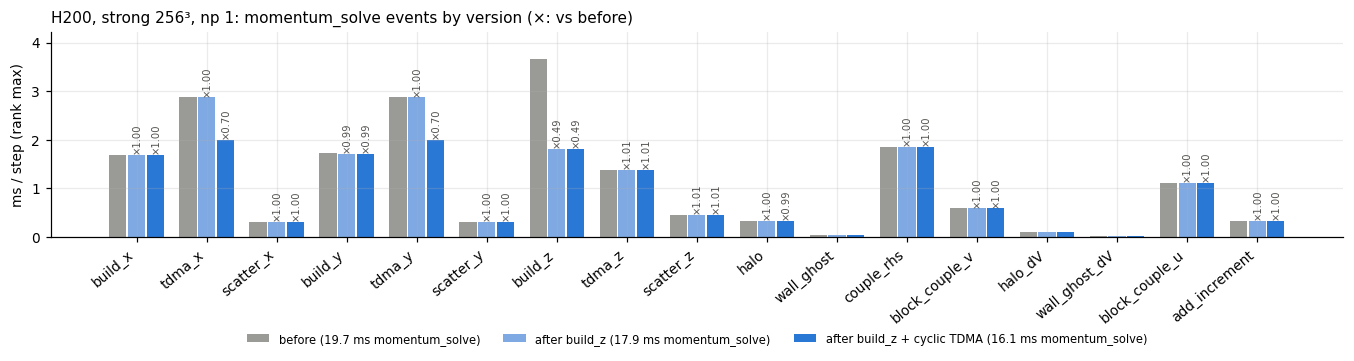

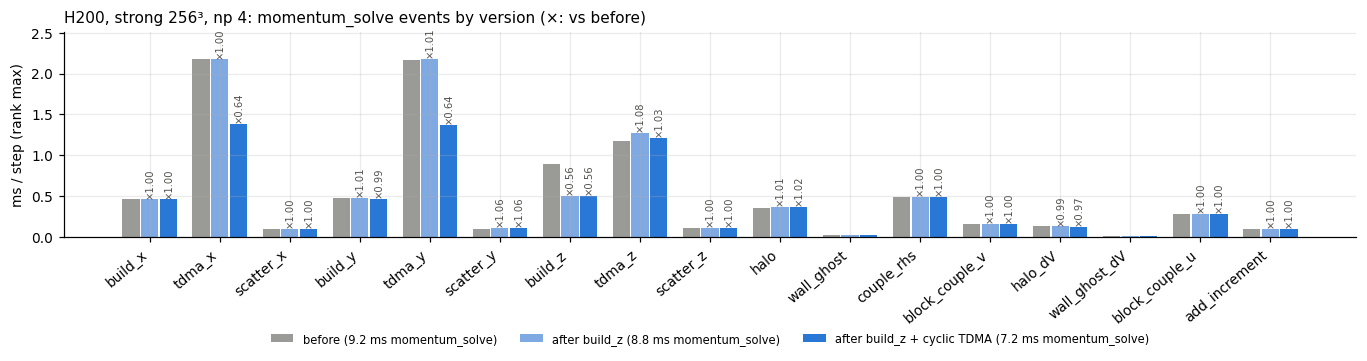

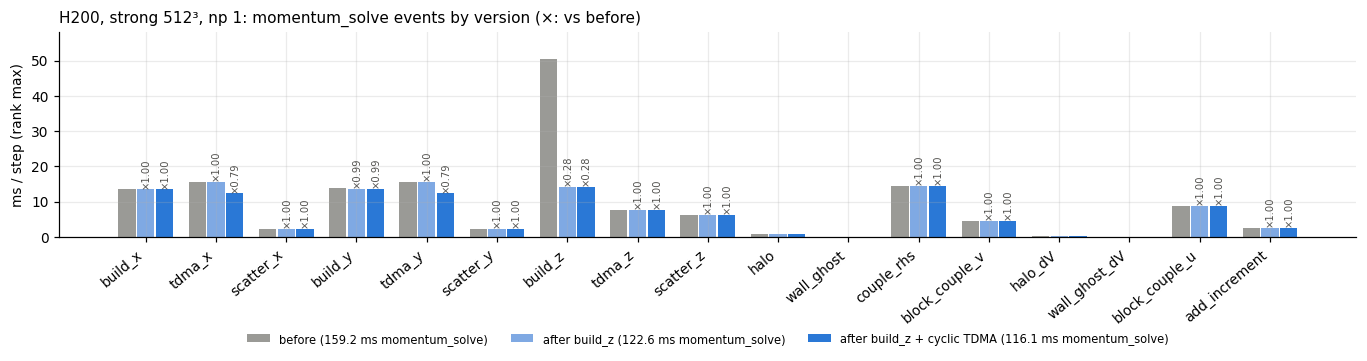

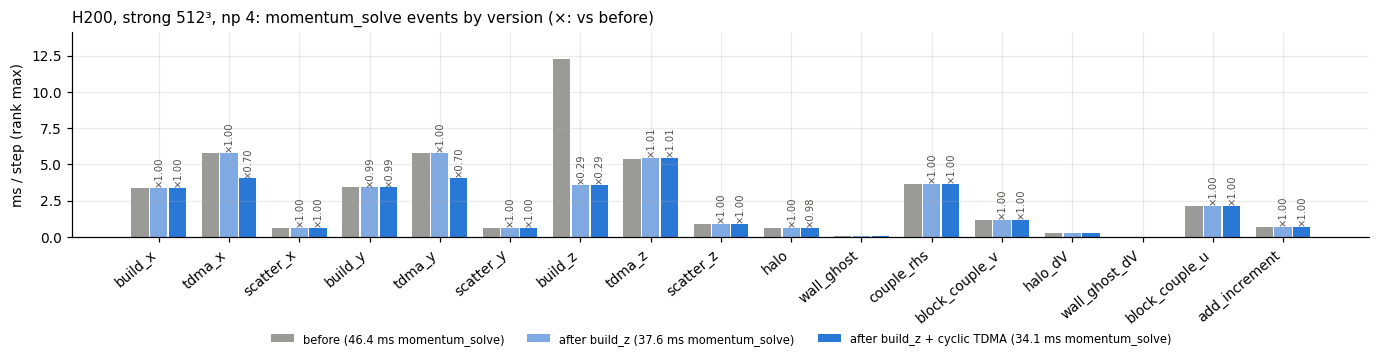

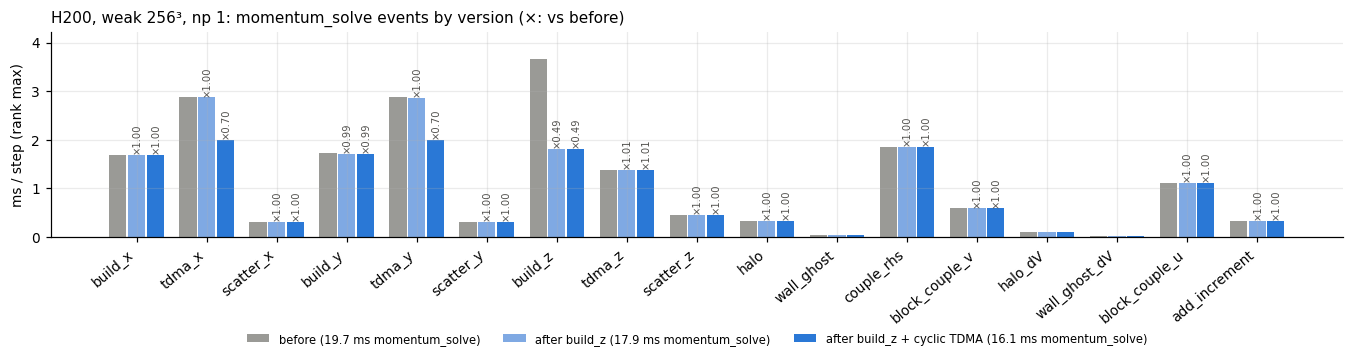

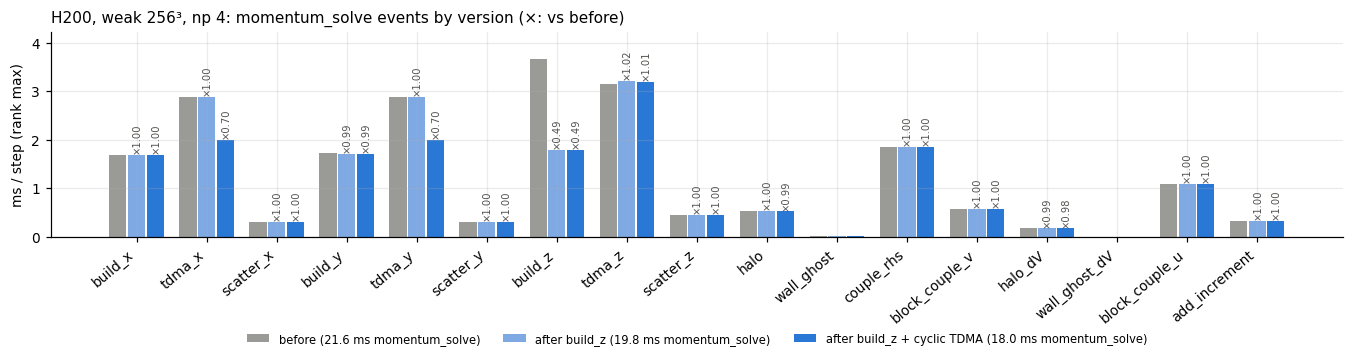

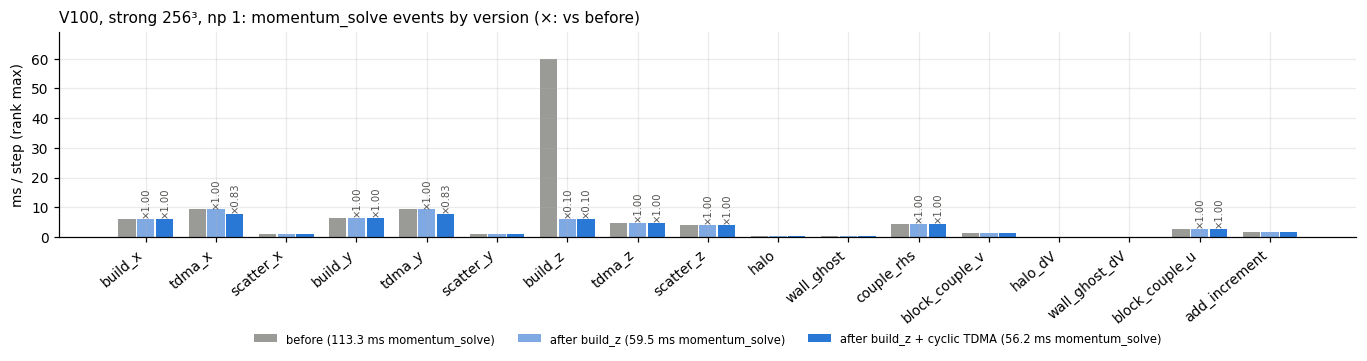

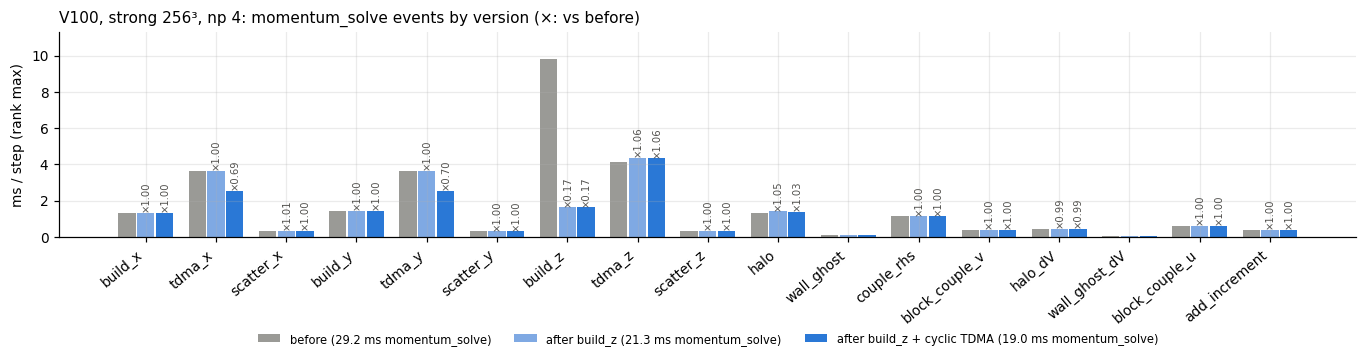

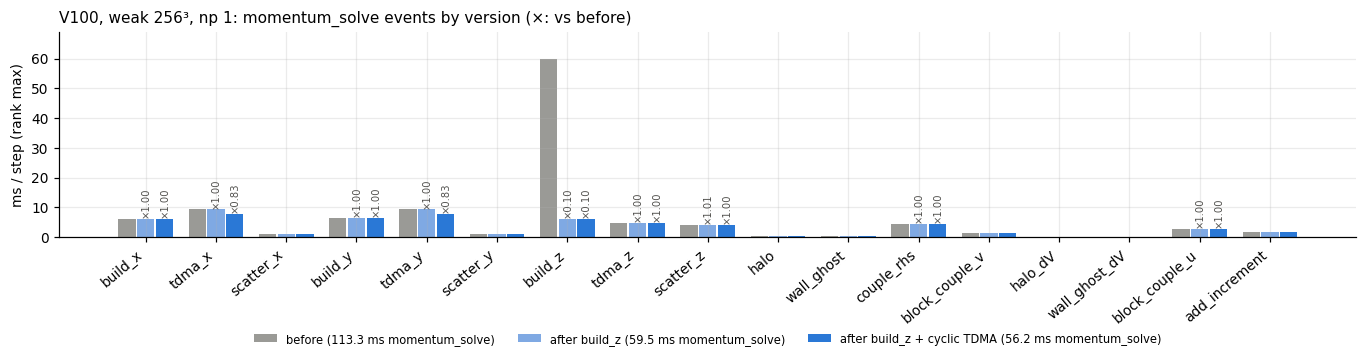

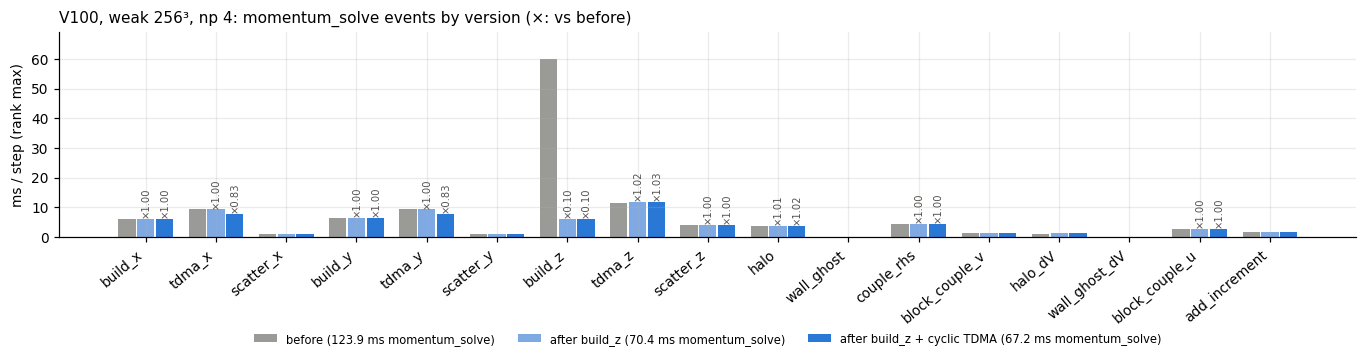

In [ ]:
def plot_before_after_events(mode, hw, n, np_):
    vers = [v for v in VERS if (hw, v, mode, n, np_) in cases]
    if len(vers) < 2:
        return
    fig, ax = plt.subplots(figsize=(12.5, 3.8))
    xs = np.arange(len(EVENTS)); w = 0.8 / len(vers)
    vb = np.array([event_time(cases[(hw, vers[0], mode, n, np_)], e) for e in EVENTS])
    vmax = vb.max()
    for j, ver in enumerate(vers):
        k = (hw, ver, mode, n, np_)
        vals = np.array([event_time(cases[k], e) for e in EVENTS]); vmax = max(vmax, vals.max())
        pos = xs - 0.4 + w * (j + 0.5)
        ax.bar(pos, vals, w * 0.92, color=VER_COLOR[ver], label=f"{VER_LABEL[ver]} ({cases[k]['momentum_solve']:.1f} ms momentum_solve)")
        if j > 0:
            for x, b, a in zip(pos, vb, vals):
                if b > 0.03 * vb.max():
                    ax.annotate(f"×{a / b:.2f}", (x, a), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=6.5, color="#52514e", rotation=90)
    ax.set_xticks(xs); ax.set_xticklabels(EVENTS, rotation=40, ha="right"); ax.set_ylabel("ms / step (rank max)")
    ax.set_title(f"{HW_NAME[hw]}, {mode} {n}³, np {np_}: momentum_solve events by version (×: vs before)", fontsize=10, loc="left")
    ax.set_ylim(0, vmax * 1.15)
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.42), ncol=3, fontsize=7.5)   # 축 아래 — 제목과 안 겹친다
    plt.tight_layout()

for hw in ("h200", "a100", "v100"):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            for np_ in (1, 4, 8):
                plot_before_after_events(mode, hw, n, np_)
plt.show()

## 3. 스텝 전체와 상위 구간 — 전/후 (np 별)

step_total, momentum_solve, scalar_solve, momentum_rhs, pressure_solve 의 전/후. build_z 는 momentum_solve 안에만 있으니
scalar_solve 등은 그대로여야 한다 (z 조립의 같은 문제가 scalar 에도 남아 있다 — 다음 회차).

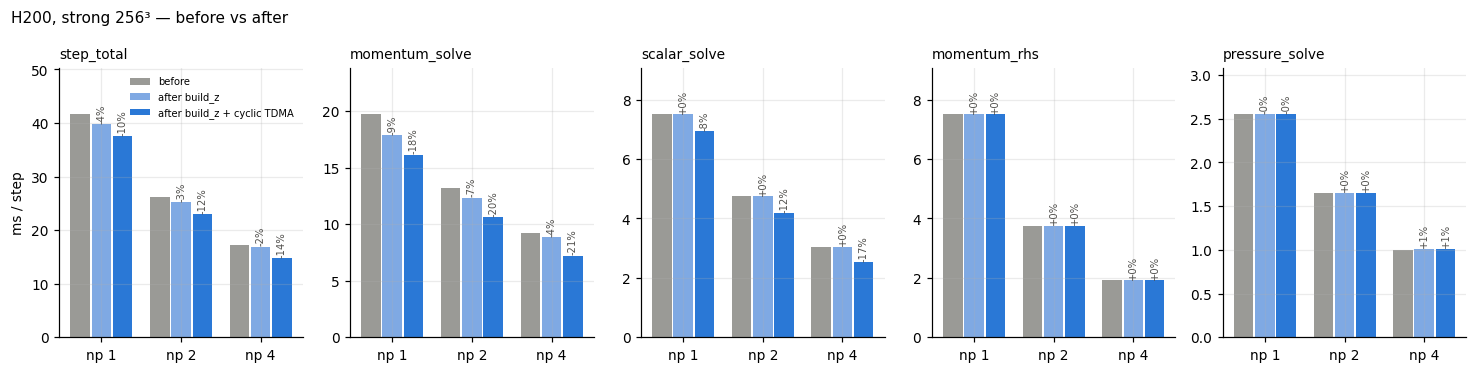

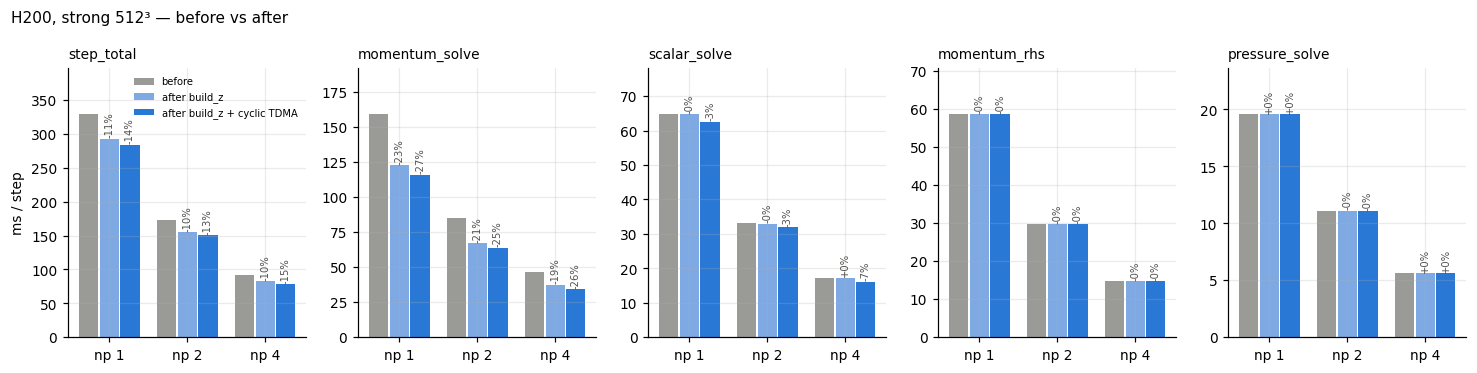

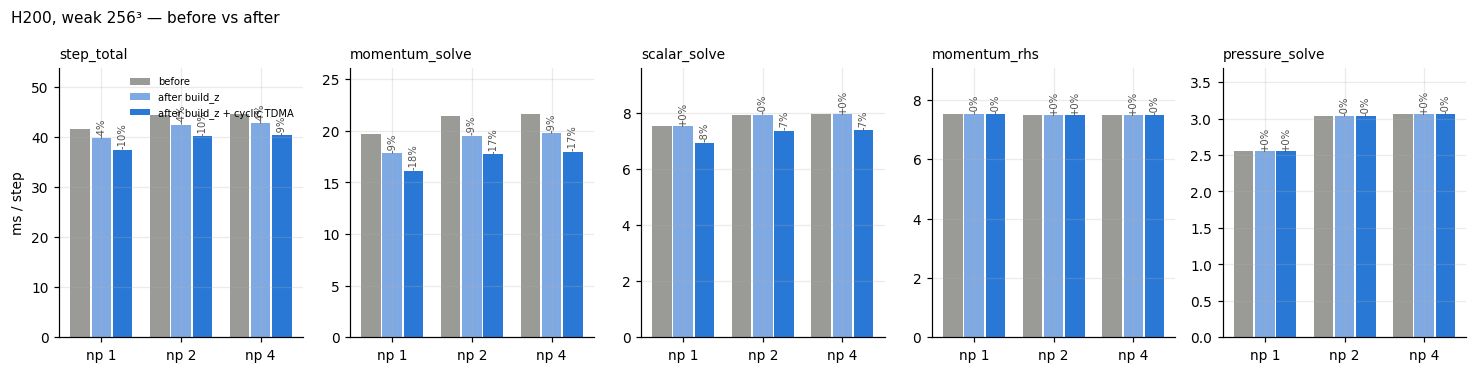

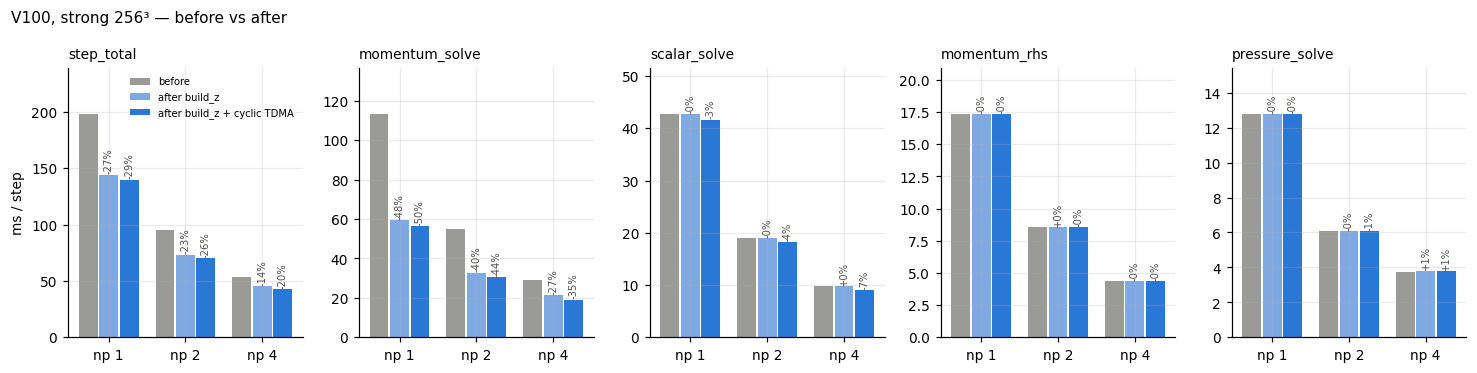

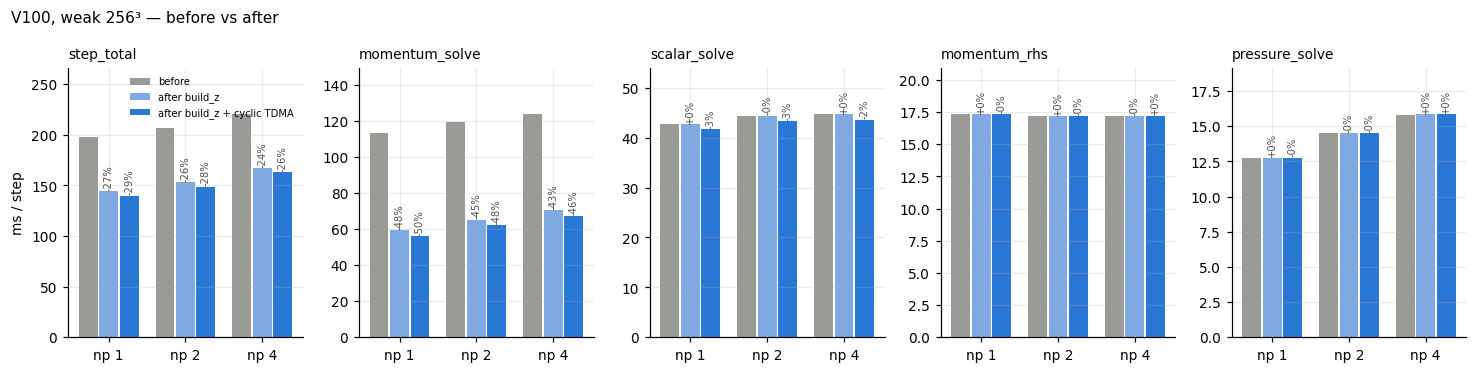

In [ ]:
def plot_top_before_after(mode, hw, n):
    vers = [v for v in VERS if any(k[:4] == (hw, v, mode, n) for k in cases)]
    nps = sorted({k[4] for k in cases if k[0] == hw and k[2:4] == (mode, n)})
    if len(vers) < 2:
        return
    fig, axes = plt.subplots(1, len(TOP), figsize=(2.7 * len(TOP), 3.4))
    for ax, phase in zip(axes, TOP):
        xs = np.arange(len(nps)); w = 0.8 / len(vers)
        for j, ver in enumerate(vers):
            vals = [cases.get((hw, ver, mode, n, p), {}).get(phase, np.nan) for p in nps]
            pos = xs - 0.4 + w * (j + 0.5)
            ax.bar(pos, vals, w * 0.92, color=VER_COLOR[ver], label=VER_LABEL[ver])
            if j > 0:
                for x, p, a in zip(pos, nps, vals):
                    b = cases.get((hw, vers[0], mode, n, p), {}).get(phase)
                    if b and a == a:
                        ax.annotate(f"{100 * (a / b - 1):+.0f}%", (x, a), xytext=(0, 2), textcoords="offset points", ha="center", fontsize=6.5, color="#52514e", rotation=90)
        ax.set_xticks(xs); ax.set_xticklabels([f"np {p}" for p in nps]); ax.set_title(phase, fontsize=9, loc="left")
        ax.set_ylim(0, ax.get_ylim()[1] * 1.15)
    axes[0].set_ylabel("ms / step"); axes[0].legend(frameon=False, fontsize=6.5)
    fig.suptitle(f"{HW_NAME[hw]}, {mode} {n}³ — before vs after", fontsize=10, x=0.01, ha="left")
    fig.tight_layout()

for hw in ("h200", "a100", "v100"):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            plot_top_before_after(mode, hw, n)
plt.show()

## 4. Scaling 곡선 — 전/후 (step_total 과 build_z)

step_total, build_z, 효율. 회색 점선 = 이상선. 색 = 하드웨어, 선·마커 = 전(점선, 작은 빈 원) / 1회차(파선, 큰 빈 사각형) / 2회차(실선, 채운 원).

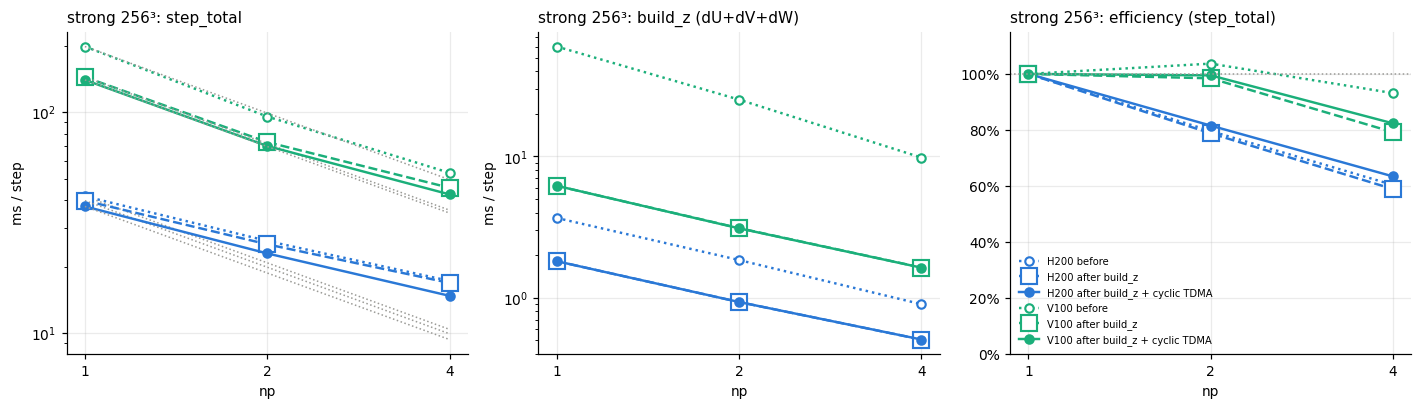

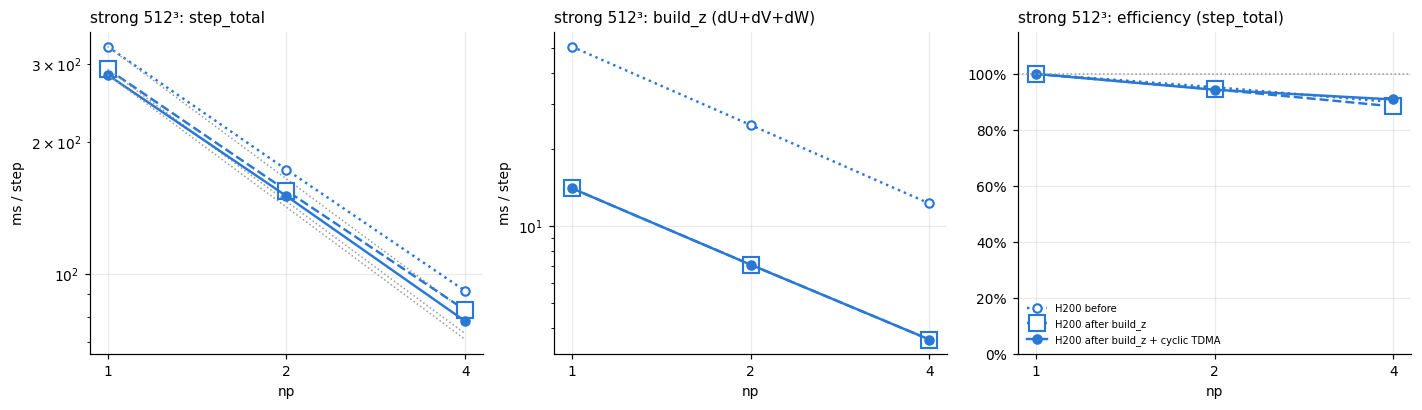

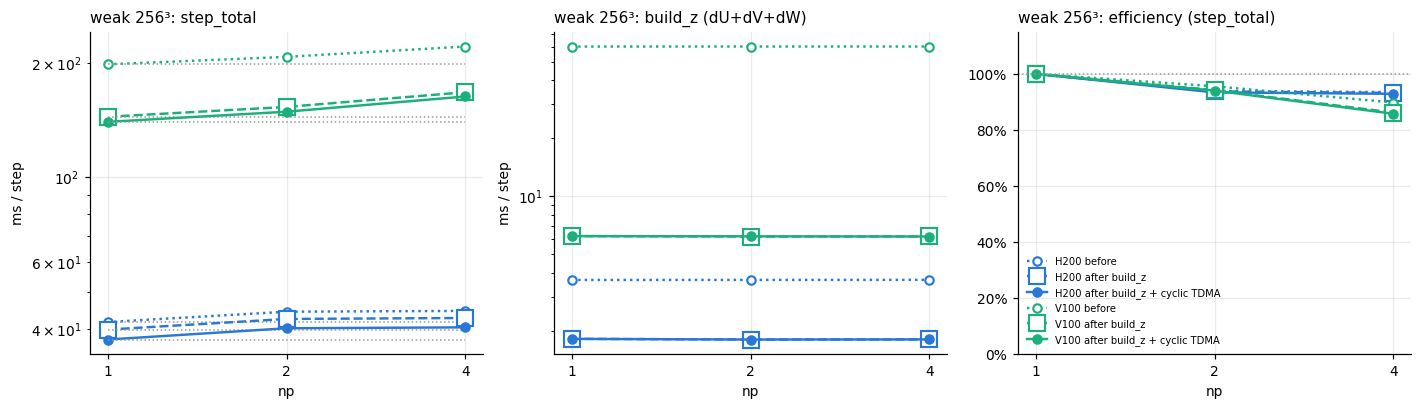

In [ ]:
def series(hw, ver, mode, n, phase=None, event=None):
    keys = sorted(k for k in cases if k[:4] == (hw, ver, mode, n))
    x = np.array([k[4] for k in keys], float)
    y = np.array([cases[k][phase] if phase else event_time(cases[k], event) for k in keys])
    return x, y

def plot_scaling_before_after(mode, n):
    hws = sorted({k[0] for k in cases if k[2:4] == (mode, n)})
    if not hws:
        return
    nps = sorted({k[4] for k in cases if k[2:4] == (mode, n)})
    fig, (ax_t, ax_z, ax_e) = plt.subplots(1, 3, figsize=(13, 3.8))
    for hw in hws:
        # 전 = 점선·작은 빈 원, 1회차 = 파선·큰 빈 사각형, 2회차 = 실선·채운 원
        for ver, ls, mk, ms, mfc in (("before", ":", "o", 5.5, "white"), ("after", "--", "s", 10, "white"), ("after2", "-", "o", 5.5, HW_COLOR[hw])):
            x, y = series(hw, ver, mode, n, phase="step_total")
            if len(x) == 0:
                continue
            ax_t.plot(x, y, ls, marker=mk, color=HW_COLOR[hw], lw=1.6, ms=ms, mfc=mfc, mew=1.4, label=f"{HW_NAME[hw]} {VER_LABEL[ver]}")
            if len(x) >= 2:
                ideal = y[0] * x[0] / x if mode == "strong" else np.full_like(y, y[0])
                ax_t.plot(x, ideal, ":", color="#9a9a96", lw=1)
                eff = (y[0] / y) / (x / x[0]) if mode == "strong" else y[0] / y
                ax_e.plot(x, eff, ls, marker=mk, color=HW_COLOR[hw], lw=1.6, ms=ms, mfc=mfc, mew=1.4, label=f"{HW_NAME[hw]} {VER_LABEL[ver]}")
            xz, yz = series(hw, ver, mode, n, event="build_z")
            ax_z.plot(xz, yz, ls, marker=mk, color=HW_COLOR[hw], lw=1.6, ms=ms, mfc=mfc, mew=1.4)
    for ax, title in ((ax_t, "step_total"), (ax_z, "build_z (dU+dV+dW)")):
        ax.set_xscale("log", base=2); ax.set_yscale("log")
        ax.xaxis.set_major_locator(FixedLocator(nps)); ax.xaxis.set_minor_formatter(NullFormatter()); ax.set_xticklabels([str(p) for p in nps])
        ax.set_xlabel("np"); ax.set_ylabel("ms / step"); ax.set_title(f"{mode} {n}³: {title}", fontsize=10, loc="left")
    ax_e.set_xscale("log", base=2); ax_e.xaxis.set_major_locator(FixedLocator(nps)); ax_e.xaxis.set_minor_formatter(NullFormatter()); ax_e.set_xticklabels([str(p) for p in nps])
    ax_e.axhline(1, color="#9a9a96", ls=":", lw=1); ax_e.set_ylim(0, 1.15); ax_e.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax_e.set_xlabel("np"); ax_e.set_title(f"{mode} {n}³: efficiency (step_total)", fontsize=10, loc="left")
    ax_e.legend(frameon=False, loc="lower left", fontsize=6.5)
    fig.tight_layout()

for mode in ("strong", "weak"):
    for n in (256, 512):
        plot_scaling_before_after(mode, n)
plt.show()

## 5. 요약표

In [ ]:
def tdma_xy(ph):
    return sum(event_time(ph, e) for e in ("tdma_x", "tdma_y"))
print(f"{'hw':5s} {'mode':6s} {'n':4s} {'np':3s} | {'step: before':>12s} {'r1':>7s} {'r2':>7s} {'gain':>6s} | {'momentum':>9s} {'r1':>7s} {'r2':>7s} | {'tdma_xy':>8s} {'r2':>7s} {'x':>5s}")
for hw in ("h200", "a100", "v100"):
    for mode in ("strong", "weak"):
        for n in (256, 512):
            for np_ in (1, 2, 4, 8):
                kb, k1, k2 = [(hw, v, mode, n, np_) for v in VERS]
                if kb not in cases:
                    continue
                b = cases[kb]; a1 = cases.get(k1); a2 = cases.get(k2)
                f = lambda c, key: f"{c[key]:7.1f}" if c else "      -"
                last = a2 or a1
                gain = f"{100*(1-last['step_total']/b['step_total']):5.0f}%" if last else "     -"
                print(f"{hw:5s} {mode:6s} {n:<4d} {np_:<3d} | {b['step_total']:12.1f} {f(a1,'step_total')} {f(a2,'step_total')} {gain} | "
                      f"{b['momentum_solve']:9.1f} {f(a1,'momentum_solve')} {f(a2,'momentum_solve')} | {tdma_xy(b):8.2f} {tdma_xy(a2) if a2 else float('nan'):7.2f} {tdma_xy(b)/tdma_xy(a2) if a2 else float('nan'):5.1f}")

hw    mode   n    np  | step: before      r1      r2   gain |  momentum      r1      r2 |  tdma_xy      r2     x
h200  strong 256  1   |         41.7    39.8    37.5    10% |      19.7    17.9    16.1 |     5.74    4.01   1.4
h200  strong 256  2   |         26.2    25.3    23.0    12% |      13.2    12.3    10.6 |     4.93    3.22   1.5
h200  strong 256  4   |         17.3    16.9    14.8    14% |       9.2     8.8     7.2 |     4.35    2.76   1.6
h200  strong 512  1   |        329.2   292.6   283.9    14% |     159.2   122.6   116.1 |    31.26   24.75   1.3
h200  strong 512  2   |        172.8   154.8   150.5    13% |      85.1    67.2    63.9 |    15.72   12.42   1.3
h200  strong 512  4   |         91.5    82.8    78.1    15% |      46.4    37.6    34.1 |    11.53    8.09   1.4
h200  weak   256  1   |         41.7    39.8    37.5    10% |      19.7    17.9    16.1 |     5.75    4.01   1.4
h200  weak   256  2   |         44.4    42.5    40.1    10% |      21.4    19.5    17.8 |     5.